# Practical Assignment 2: Problem Solving Through Search

**Subject:** Artificial Intelligence / Machine Learning
**Practical:** Uninformed, informed, local search and constraint satisfaction

**Name :- *Shravani Minache*
**Div:-A  Batch:-A3**
**PRN :- 202401040304**

## Aim
Implement and compare search techniques on standard benchmark problems. Measure solution quality, states explored and run time.

| Search family | Algorithms | Benchmark problem |
|---|---|---|
| Uninformed | BFS, DFS, Uniform Cost Search | Romania road map (Arad to Bucharest) |
| Informed | Greedy Best-First, A* | Same map, straight-line distance heuristic |
| Local search | Hill Climbing (random restarts), Simulated Annealing | Travelling Salesman Problem, 25 random cities |
| Constraint satisfaction | Backtracking, MRV + Forward Checking | 9x9 Sudoku |

## 1. Imports and setup

In [1]:
import heapq
import math
import os
import random
import time
from collections import deque

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Setup done.")

Setup done.


## 2. Dataset: Romania road map

The map from Russell & Norvig, *AIMA* . Nodes are cities, edge weights are road distances in km. The heuristic is the straight-line distance (SLD) from each city to Bucharest, from the same source.

Cities: 20 | Roads: 23


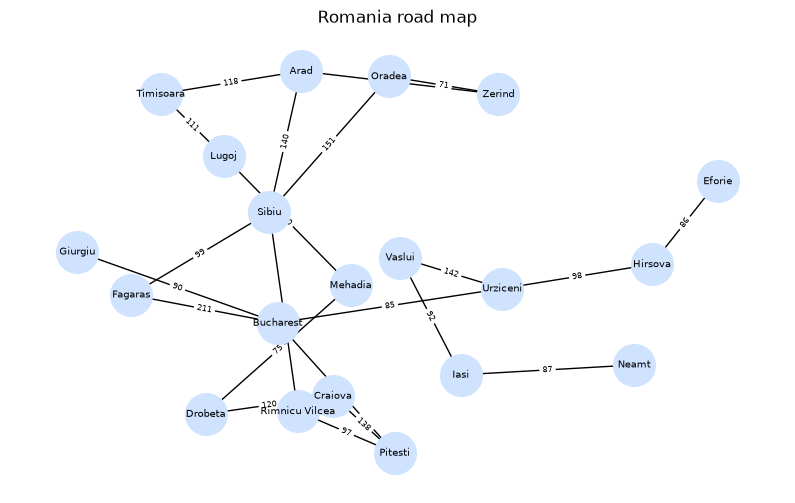

In [2]:
roads = [
    ("Arad", "Zerind", 75), ("Arad", "Sibiu", 140), ("Arad", "Timisoara", 118),
    ("Zerind", "Oradea", 71), ("Oradea", "Sibiu", 151), ("Timisoara", "Lugoj", 111),
    ("Lugoj", "Mehadia", 70), ("Mehadia", "Drobeta", 75), ("Drobeta", "Craiova", 120),
    ("Craiova", "Rimnicu Vilcea", 146), ("Craiova", "Pitesti", 138),
    ("Sibiu", "Fagaras", 99), ("Sibiu", "Rimnicu Vilcea", 80),
    ("Rimnicu Vilcea", "Pitesti", 97), ("Pitesti", "Bucharest", 101),
    ("Fagaras", "Bucharest", 211), ("Bucharest", "Giurgiu", 90),
    ("Bucharest", "Urziceni", 85), ("Urziceni", "Hirsova", 98),
    ("Urziceni", "Vaslui", 142), ("Hirsova", "Eforie", 86),
    ("Vaslui", "Iasi", 92), ("Iasi", "Neamt", 87),
]
sld_to_bucharest = {
    "Arad": 366, "Bucharest": 0, "Craiova": 160, "Drobeta": 242, "Eforie": 161,
    "Fagaras": 176, "Giurgiu": 77, "Hirsova": 151, "Iasi": 226, "Lugoj": 244,
    "Mehadia": 241, "Neamt": 234, "Oradea": 380, "Pitesti": 100,
    "Rimnicu Vilcea": 193, "Sibiu": 253, "Timisoara": 329, "Urziceni": 80,
    "Vaslui": 199, "Zerind": 374,
}

G = nx.Graph()
for a, b, d in roads:
    G.add_edge(a, b, cost=d)

print("Cities:", G.number_of_nodes(), "| Roads:", G.number_of_edges())

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=SEED, k=0.9)
nx.draw_networkx(G, pos, node_size=900, node_color="#cfe3ff", font_size=7)
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "cost"), font_size=6)
plt.title("Romania road map")
plt.axis("off")
plt.show()

In [3]:
os.makedirs("data", exist_ok=True)
pd.DataFrame(roads, columns=["city_a", "city_b", "km"]).to_csv("data/romania_roads.csv", index=False)
pd.DataFrame(sld_to_bucharest.items(), columns=["city", "sld_to_bucharest_km"]).to_csv("data/romania_sld.csv", index=False)
pd.DataFrame(roads, columns=["city_a", "city_b", "km"]).head()

,city_a,city_b,km
0,Arad,Zerind,75
1,Arad,Sibiu,140
2,Arad,Timisoara,118
3,Zerind,Oradea,71
4,Oradea,Sibiu,151


## 3. Problem and metrics

Task: route from **Arad** to **Bucharest**. BFS and DFS ignore distances and count every road as one step. UCS, Greedy and A* use the km costs.

Recorded per algorithm:

- **Path** returned
- **Path cost** in km
- **Path length** in roads
- **Expanded nodes**: nodes taken off the frontier
- **Time** in ms

The SLD heuristic is admissible: a straight line is never longer than any road route.

In [4]:
START, GOAL = "Arad", "Bucharest"

def path_cost(graph, path):
    return sum(graph[u][v]["cost"] for u, v in zip(path, path[1:])) if path else None

def h(node):
    return sld_to_bucharest[node]

def build_path(parent, goal):
    if goal not in parent:
        return None
    out, cur = [], goal
    while cur is not None:
        out.append(cur)
        cur = parent[cur]
    return out[::-1]

def package(name, graph, parent, expanded):
    path = build_path(parent, GOAL)
    return {"algorithm": name, "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": path_cost(graph, path)}

def timed(fn, *args):
    t0 = time.perf_counter()
    res = fn(*args)
    res["time_ms"] = (time.perf_counter() - t0) * 1000
    return res

# admissibility check: h(n) must not exceed the true cheapest cost to the goal
true_cost = nx.single_source_dijkstra_path_length(G, GOAL, weight="cost")
assert all(h(n) <= true_cost[n] for n in G), "heuristic is not admissible"
print("Heuristic is admissible. h(Arad) =", h(START), "| true cost =", true_cost[START])

Heuristic is admissible. h(Arad) = 366 | true cost = 418


## 4. Uninformed search

- **BFS** expands level by level. Fewest roads, not fewest km.
- **DFS** goes deep first. Fast sometimes, no optimality guarantee.
- **UCS** expands the cheapest frontier node by accumulated cost. Optimal for non-negative costs.

In [5]:
def bfs(graph, start, goal):
    frontier, parent, expanded = deque([start]), {start: None}, 0
    while frontier:
        node = frontier.popleft()
        expanded += 1
        if node == goal:
            break
        for nb in sorted(graph.neighbors(node)):
            if nb not in parent:
                parent[nb] = node
                frontier.append(nb)
    return package("BFS", graph, parent, expanded)

def dfs(graph, start, goal):
    stack, parent, expanded = [start], {start: None}, 0
    while stack:
        node = stack.pop()
        expanded += 1
        if node == goal:
            break
        for nb in sorted(graph.neighbors(node), reverse=True):
            if nb not in parent:
                parent[nb] = node
                stack.append(nb)
    return package("DFS", graph, parent, expanded)

def ucs(graph, start, goal):
    frontier, parent, best, expanded = [(0, start)], {start: None}, {start: 0}, 0
    while frontier:
        g, node = heapq.heappop(frontier)
        if g > best[node]:
            continue
        expanded += 1
        if node == goal:
            break
        for nb in graph.neighbors(node):
            ng = g + graph[node][nb]["cost"]
            if ng < best.get(nb, math.inf):
                best[nb], parent[nb] = ng, node
                heapq.heappush(frontier, (ng, nb))
    return package("UCS", graph, parent, expanded)

uninformed = [timed(f, G, START, GOAL) for f in (bfs, dfs, ucs)]
for r in uninformed:
    print(f"{r['algorithm']:4} {' > '.join(r['path'])} | {r['path_cost']} km | expanded {r['expanded']}")

BFS  Arad > Sibiu > Fagaras > Bucharest | 450 km | expanded 9
DFS  Arad > Sibiu > Fagaras > Bucharest | 450 km | expanded 4
UCS  Arad > Sibiu > Rimnicu Vilcea > Pitesti > Bucharest | 418 km | expanded 13


## 5. Informed search

- **Greedy Best-First** orders the frontier by `h(n)` only. Quick, can pick a costly route.
- **A\*** orders by `f(n) = g(n) + h(n)`. With an admissible heuristic it returns an optimal path.

In [6]:
def greedy(graph, start, goal):
    frontier, parent, seen, expanded = [(h(start), start)], {start: None}, set(), 0
    while frontier:
        _, node = heapq.heappop(frontier)
        if node in seen:
            continue
        seen.add(node)
        expanded += 1
        if node == goal:
            break
        for nb in graph.neighbors(node):
            if nb not in parent:
                parent[nb] = node
                heapq.heappush(frontier, (h(nb), nb))
    return package("Greedy Best-First", graph, parent, expanded)

def a_star(graph, start, goal):
    frontier, parent, best, expanded = [(h(start), 0, start)], {start: None}, {start: 0}, 0
    while frontier:
        _, g, node = heapq.heappop(frontier)
        if g > best[node]:
            continue
        expanded += 1
        if node == goal:
            break
        for nb in graph.neighbors(node):
            ng = g + graph[node][nb]["cost"]
            if ng < best.get(nb, math.inf):
                best[nb], parent[nb] = ng, node
                heapq.heappush(frontier, (ng + h(nb), ng, nb))
    return package("A*", graph, parent, expanded)

informed = [timed(f, G, START, GOAL) for f in (greedy, a_star)]
for r in informed:
    print(f"{r['algorithm']:18} {' > '.join(r['path'])} | {r['path_cost']} km | expanded {r['expanded']}")

Greedy Best-First  Arad > Sibiu > Fagaras > Bucharest | 450 km | expanded 4
A*                 Arad > Sibiu > Rimnicu Vilcea > Pitesti > Bucharest | 418 km | expanded 6


## 6. Compare graph-search results

Time on a 20-node graph is noise-level, so each run is repeated 200 times and averaged. Expanded nodes and path cost are the metrics that matter here.

,algorithm,path_length,path_cost,expanded,avg_time_ms
0,BFS,3,450,9,0.0097
1,DFS,3,450,4,0.0053
2,UCS,4,418,13,0.0286
3,Greedy Best-First,3,450,4,0.0097
4,A*,4,418,6,0.0199


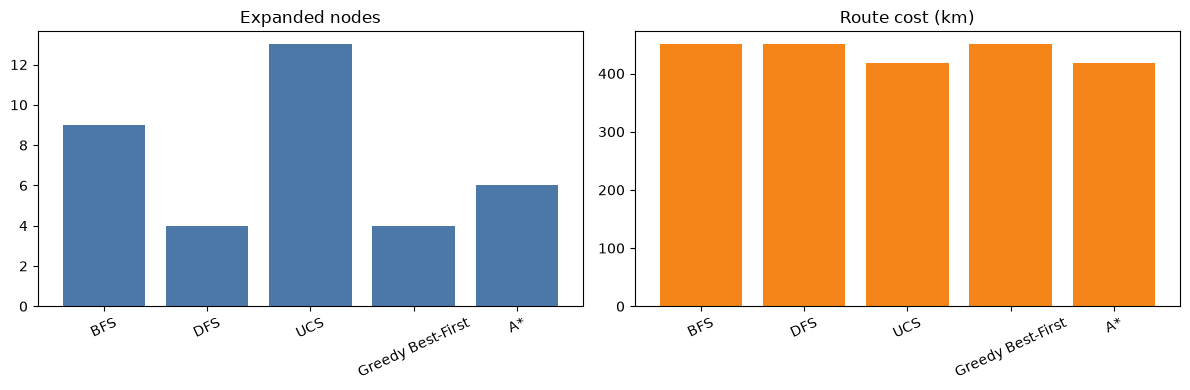

In [7]:
def avg_time(fn, reps=200):
    t0 = time.perf_counter()
    for _ in range(reps):
        fn(G, START, GOAL)
    return (time.perf_counter() - t0) * 1000 / reps

graph_results = uninformed + informed
fns = {"BFS": bfs, "DFS": dfs, "UCS": ucs, "Greedy Best-First": greedy, "A*": a_star}
table = pd.DataFrame([{**{k: r[k] for k in ("algorithm", "path_length", "path_cost", "expanded")},
                       "avg_time_ms": avg_time(fns[r["algorithm"]])} for r in graph_results])
display(table.round({"avg_time_ms": 4}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(table["algorithm"], table["expanded"], color="#4c78a8")
ax[0].set_title("Expanded nodes"); ax[0].tick_params(axis="x", rotation=25)
ax[1].bar(table["algorithm"], table["path_cost"], color="#f58518")
ax[1].set_title("Route cost (km)"); ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## 7. Local search: Travelling Salesman Problem

25 random cities in a unit square. A state is a tour (a permutation of cities). The objective is total tour length, lower is better. Neighbours are produced by **2-opt**: reverse a segment of the tour.

- **Hill Climbing:** take the best improving 2-opt move until none exists. Gets stuck in local minima, so we add **random restarts**.
- **Simulated Annealing:** accept worse moves with probability `exp(-delta / T)` while `T` cools.
- **Nearest Neighbour:** greedy constructive baseline for reference.

In [8]:
N_CITIES = 25
rng_cities = np.random.default_rng(SEED)
cities = rng_cities.random((N_CITIES, 2))
DIST = np.linalg.norm(cities[:, None, :] - cities[None, :, :], axis=2)

def tour_length(tour):
    return sum(DIST[tour[i], tour[(i + 1) % len(tour)]] for i in range(len(tour)))

def two_opt(tour, i, j):
    return tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]

def nearest_neighbour(start=0):
    tour, left = [start], set(range(N_CITIES)) - {start}
    while left:
        nxt = min(left, key=lambda c: DIST[tour[-1], c])
        tour.append(nxt); left.remove(nxt)
    return tour

def hill_climb(rng):
    tour = list(range(N_CITIES)); rng.shuffle(tour)
    cur, steps = tour_length(tour), 0
    while True:
        best_move, best_len = None, cur
        for i in range(1, N_CITIES - 1):
            for j in range(i + 1, N_CITIES):
                cand = two_opt(tour, i, j)
                L = tour_length(cand)
                if L < best_len - 1e-12:
                    best_move, best_len = cand, L
        if best_move is None:
            break
        tour, cur, steps = best_move, best_len, steps + 1
    return tour, cur, steps

def hill_climb_restarts(seed, restarts=10):
    rng = random.Random(seed)
    best = (None, math.inf, 0)
    total_steps = 0
    for _ in range(restarts):
        t, L, s = hill_climb(rng)
        total_steps += s
        if L < best[1]:
            best = (t, L, s)
    return best[0], best[1], total_steps

def simulated_annealing(seed, T0=1.0, cooling=0.9995, max_steps=20000):
    rng = random.Random(seed)
    tour = list(range(N_CITIES)); rng.shuffle(tour)
    cur = tour_length(tour)
    best, best_len, T = tour, cur, T0
    for step in range(1, max_steps + 1):
        i, j = sorted(rng.sample(range(1, N_CITIES), 2))
        cand = two_opt(tour, i, j)
        L = tour_length(cand)
        d = L - cur
        if d < 0 or rng.random() < math.exp(-d / max(T, 1e-12)):
            tour, cur = cand, L
            if cur < best_len:
                best, best_len = tour, cur
        T *= cooling
    return best, best_len, max_steps

nn = nearest_neighbour()
print("Nearest-neighbour baseline length:", round(tour_length(nn), 4))

Nearest-neighbour baseline length: 4.2239


In [9]:
TRIALS = 20
rows, best_tours = [], {}
for trial in range(TRIALS):
    for name, fn in (("Hill Climbing (10 restarts)", hill_climb_restarts), ("Simulated Annealing", simulated_annealing)):
        t0 = time.perf_counter()
        tour, L, steps = fn(SEED + trial)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"algorithm": name, "trial": trial + 1, "tour_length": L, "steps": steps, "time_ms": ms})
        if name not in best_tours or L < best_tours[name][1]:
            best_tours[name] = (tour, L)

local_results = pd.DataFrame(rows)
local_summary = local_results.groupby("algorithm").agg(
    best_length=("tour_length", "min"),
    mean_length=("tour_length", "mean"),
    std_length=("tour_length", "std"),
    mean_steps=("steps", "mean"),
    mean_time_ms=("time_ms", "mean"),
).reset_index()
local_summary.loc[len(local_summary)] = ["Nearest Neighbour (baseline)", tour_length(nn), tour_length(nn), 0.0, 0, 0.0]
display(local_summary.round(3))

,algorithm,best_length,mean_length,std_length,mean_steps,mean_time_ms
0,Hill Climbing (10 restarts),3.513,3.513,0.000,206.35,558.494
1,Simulated Annealing,3.513,3.521,0.015,20000.00,276.190
2,Nearest Neighbour (baseline),4.224,4.224,0.000,0.00,0.000


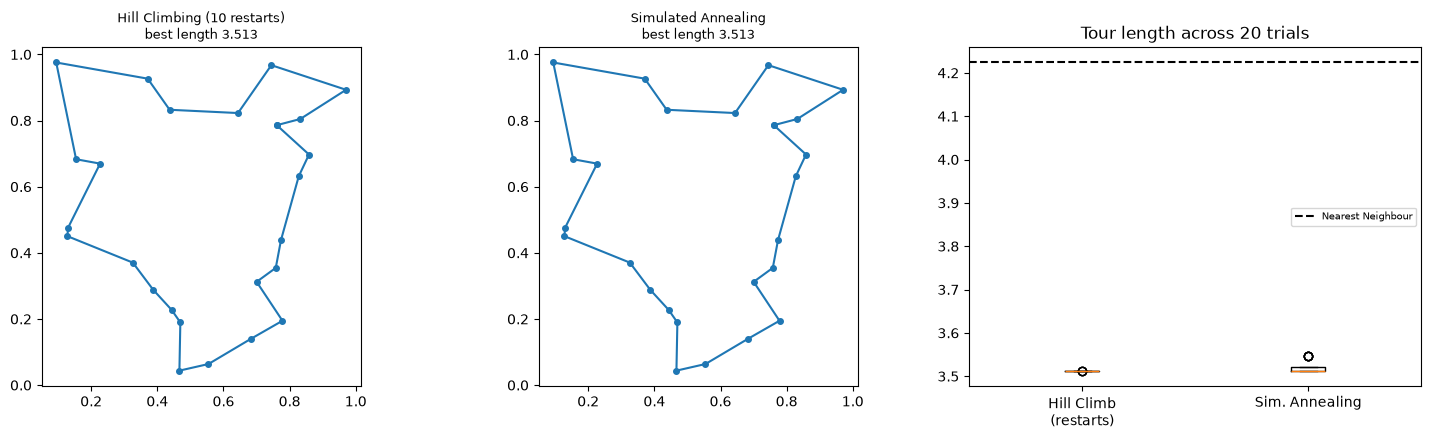

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (name, (tour, L)) in zip(ax[:2], best_tours.items()):
    pts = cities[tour + [tour[0]]]
    a.plot(pts[:, 0], pts[:, 1], "-o", ms=4)
    a.set_title(f"{name}\nbest length {L:.3f}", fontsize=9)
    a.set_aspect("equal")
groups = [g["tour_length"].values for _, g in local_results.groupby("algorithm")]
labels = ["Hill Climb\n(restarts)" if "Hill" in n else "Sim. Annealing" for n in sorted(local_results["algorithm"].unique())]
ax[2].boxplot(groups)
ax[2].set_xticklabels(labels)
ax[2].axhline(tour_length(nn), color="k", ls="--", label="Nearest Neighbour")
ax[2].set_title("Tour length across 20 trials"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Constraint Satisfaction Problem: Sudoku

Variables: 81 cells. Domain: digits 1 to 9 (a given digit fixes the domain). Constraints: no repeated digit in a row, column or 3x3 box.

1. **Basic Backtracking:** fill the next empty cell in order, undo on conflict.
2. **MRV + Forward Checking:** pick the empty cell with the fewest legal digits, then remove the chosen digit from its peers' domains. Backtrack at once if any domain becomes empty.

Two puzzles: an easy one from the Wikipedia Sudoku article, and a harder one where cell-order matters more.

In [11]:
PUZZLES = {
    "easy": "530070000600195000098000060800060003400803001700020006060000280000419005000080079",
    "hard": "000000907000420180000705026100904000050000040000507009920108000034059000507000000",
}

CELLS = [(r, c) for r in range(9) for c in range(9)]
def peers_of(r, c):
    row = {(r, k) for k in range(9)}
    col = {(k, c) for k in range(9)}
    br, bc = 3 * (r // 3), 3 * (c // 3)
    box = {(br + i, bc + j) for i in range(3) for j in range(3)}
    return (row | col | box) - {(r, c)}
PEERS = {cell: peers_of(*cell) for cell in CELLS}

def parse(s):
    return {(i // 9, i % 9): int(ch) for i, ch in enumerate(s)}

def valid_solution(grid):
    groups = [[(r, c) for c in range(9)] for r in range(9)] + \
             [[(r, c) for r in range(9)] for c in range(9)] + \
             [[(br + i, bc + j) for i in range(3) for j in range(3)] for br in (0, 3, 6) for bc in (0, 3, 6)]
    return all(sorted(grid[x] for x in g) == list(range(1, 10)) for g in groups)

def plain_backtracking(puzzle, limit=3_000_000):
    grid = dict(puzzle)
    stats = {"assignments": 0, "backtracks": 0}
    empties = [c for c in CELLS if grid[c] == 0]
    def solve(k):
        if k == len(empties):
            return True
        cell = empties[k]
        for d in range(1, 10):
            stats["assignments"] += 1
            if stats["assignments"] > limit:
                return False
            if all(grid[p] != d for p in PEERS[cell]):
                grid[cell] = d
                if solve(k + 1):
                    return True
                grid[cell] = 0
        stats["backtracks"] += 1
        return False
    ok = solve(0)
    return (grid if ok else None), stats

def mrv_fc(puzzle):
    grid = dict(puzzle)
    dom = {c: set(range(1, 10)) if grid[c] == 0 else {grid[c]} for c in CELLS}
    stats = {"assignments": 0, "backtracks": 0}
    # prune domains using the given digits
    for c in CELLS:
        if grid[c]:
            for p in PEERS[c]:
                dom[p].discard(grid[c])
    def solve():
        empties = [c for c in CELLS if grid[c] == 0]
        if not empties:
            return True
        cell = min(empties, key=lambda c: len(dom[c]))
        for d in sorted(dom[cell]):
            stats["assignments"] += 1
            grid[cell] = d
            removed, dead = [], False
            for p in PEERS[cell]:
                if grid[p] == 0 and d in dom[p]:
                    dom[p].discard(d); removed.append(p)
                    if not dom[p]:
                        dead = True; break
            if not dead and solve():
                return True
            for p in removed:
                dom[p].add(d)
            grid[cell] = 0
        stats["backtracks"] += 1
        return False
    ok = solve()
    return (grid if ok else None), stats

csp_rows = []
solutions = {}
for pname, s in PUZZLES.items():
    puzzle = parse(s)
    for name, solver in (("Backtracking", plain_backtracking), ("MRV + Forward Checking", mrv_fc)):
        t0 = time.perf_counter()
        sol, stats = solver(puzzle)
        ms = (time.perf_counter() - t0) * 1000
        csp_rows.append({"puzzle": pname, "algorithm": name, "solved": sol is not None,
                         "assignments_tried": stats["assignments"], "backtracks": stats["backtracks"],
                         "time_ms": ms})
        if sol:
            assert valid_solution(sol)
            solutions[(pname, name)] = sol

csp_comparison = pd.DataFrame(csp_rows)
display(csp_comparison.round(2))

,puzzle,algorithm,solved,assignments_tried,backtracks,time_ms
0,easy,Backtracking,True,37652,4157,63.58
1,easy,MRV + Forward Checking,True,51,0,0.88
2,hard,Backtracking,True,170978,18969,360.69
3,hard,MRV + Forward Checking,True,116,57,3.07


In [12]:
sol = solutions[("easy", "MRV + Forward Checking")]
for r in range(9):
    if r % 3 == 0 and r:
        print("------+-------+------")
    print(" | ".join(" ".join(str(sol[(r, c)]) for c in range(b, b + 3)) for b in (0, 3, 6)))

5 3 4 | 6 7 8 | 9 1 2
6 7 2 | 1 9 5 | 3 4 8
1 9 8 | 3 4 2 | 5 6 7
------+-------+------
8 5 9 | 7 6 1 | 4 2 3
4 2 6 | 8 5 3 | 7 9 1
7 1 3 | 9 2 4 | 8 5 6
------+-------+------
9 6 1 | 5 3 7 | 2 8 4
2 8 7 | 4 1 9 | 6 3 5
3 4 5 | 2 8 6 | 1 7 9


## 9. Observations

Fill in from your own run. Points to check against the output:

- BFS minimises roads, not km, so it can return a costlier route than UCS.
- DFS reached the goal, but the route depends on neighbour order.
- UCS and A* should return the same minimum cost. A* expands fewer nodes because the SLD heuristic steers it.
- Greedy (tied with DFS) expands the fewest nodes, but `h(n)` pulls it onto the Fagaras route, which costs more than the optimum.
- Hill climbing with 2-opt ends in a local minimum each restart. Compare its spread across trials with simulated annealing.
- Both local methods should beat the nearest-neighbour baseline. Neither proves optimality.
- MRV + Forward Checking tries far fewer assignments than plain backtracking, most visibly on the harder puzzle.

In [13]:
ucs_cost = next(r["path_cost"] for r in graph_results if r["algorithm"] == "UCS")
astar_cost = next(r["path_cost"] for r in graph_results if r["algorithm"] == "A*")
assert ucs_cost == astar_cost == true_cost[START], "UCS and A* must both be optimal"
assert all(r["solved"] for r in csp_rows), "Every CSP run should solve its puzzle"
assert local_summary.query("algorithm != 'Nearest Neighbour (baseline)'")["best_length"].max() <= tour_length(nn)
print("All validation checks passed.")

All validation checks passed.


## 10. Conclusion

- **Graph search:** fewest-steps and lowest-cost are different goals. Heuristics cut the work without losing optimality, provided they are admissible.
- **Local search:** restarts and random uphill moves both help against local minima. Neither guarantees the global optimum.
- **CSP:** variable ordering and early domain pruning matter more than raw speed of the loop.

Pick the method from the problem type and the heuristic available.
